# S10 — Jhonatan | Pronóstico de velocidad de la siguiente observación
**Proyecto Sello, Unidad II — CRISP-DM.** Mismos datos históricos reales de Perú que Leonardo (ADSB.lol, 26–30/12/2024).

**Pregunta:** ¿Cuál será la velocidad de una aeronave en su siguiente observación válida, dentro de un máximo de 90 segundos, utilizando solo la lectura actual?

La frecuencia de observación es irregular; no afirmar que la predicción es exactamente a 60 segundos. Las fechas de noviembre de 2026 son solo para reproducción operacional, no entrenamiento.

## 1. Comprensión del problema y carga de datos
El modelo estima velocidad de la siguiente lectura de la misma aeronave. El objetivo futuro (`lead`) se usa solamente para entrenar/evaluar, nunca como predictor. Partición: 26–28 entrenamiento, 29 validación y 30 prueba.

In [2]:
APP_NAME='S10-Jhonatan-Velocidad-Peru'
PREGUNTA='¿Cual sera la velocidad de la aeronave en su siguiente observacion (1–90 s)?'
UNIDAD='m/s'
ID_MODELO='jhonatan_velocidad'

from pathlib import Path
import json, math
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType, BooleanType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# Si Spark ya estaba iniciado sin conector Kafka, reiniciar el kernel para streaming.
PAQUETE = 'org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0'
spark = (SparkSession.builder.appName(APP_NAME).master('local[2]')
    .config('spark.jars.packages', PAQUETE)
    .config('spark.sql.session.timeZone','UTC')
    .config('spark.sql.shuffle.partitions','8')
    .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
ROOT = Path('/workspace/artifacts/s10')
ROOT.mkdir(parents=True, exist_ok=True)
RUTA = '/workspace/artifacts/s10/peru_historico_unificado'
assert Path(RUTA).exists(), f'Falta el Parquet historico: {RUTA}'
df = spark.read.parquet(RUTA)
print('Spark', spark.version)
print('Registros de origen:', df.count())
print('Fuente: ADSB.lol Peru, 26–30 diciembre de 2024. NO son vuelos de noviembre 2026.')

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-a968403b-037c-45ef-bb06-a8e0a5629b36;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.mod

Spark 4.2.0


[Stage 1:>                                                          (0 + 2) / 2]

Registros de origen: 184753
Fuente: ADSB.lol Peru, 26–30 diciembre de 2024. NO son vuelos de noviembre 2026.


## 2. Inspección y validación de datos
Usamos velocidades en **m/s**, altitud en metros, rumbo en grados y velocidades verticales en m/s. La identificación de aeronave se hace mediante ICAO24; se descartan posiciones obsoletas cuando están marcadas.

In [3]:
base=(df.filter(F.col('icao24').rlike('^[0-9a-f]{6}$'))
      .filter(F.col('eventTimestamp').isNotNull())
      .filter(F.col('velocity').between(0,400))
      .filter(F.col('latitude').between(-18.35,-0.04)&F.col('longitude').between(-81.33,-68.65))
      .filter(F.col('positionStale').isNull() | (F.lower(F.col('positionStale').cast('string'))=='false'))
      .fillna({'baroAltitude':0.0,'verticalRate':0.0,'trueTrack':0.0}))
print('Registros con velocidad valida:',base.count())
base.groupBy('fecha').agg(F.count('*').alias('observaciones'),F.countDistinct('icao24').alias('aeronaves')).orderBy('fecha').show()

Registros con velocidad valida: 175349


[Stage 7:>                                                          (0 + 2) / 2]

+----------+-------------+---------+
|     fecha|observaciones|aeronaves|
+----------+-------------+---------+
|2024-12-26|        34209|      160|
|2024-12-27|        38783|      169|
|2024-12-28|        36184|      169|
|2024-12-29|        36120|      167|
|2024-12-30|        30053|      171|
+----------+-------------+---------+



## 3. Etiqueta `lead(velocity)` por aeronave y features actuales
Construimos pares sucesivos de un ICAO24, exigiendo separación temporal **1–90 segundos** y el mismo día UTC. Esto limita emparejamientos cruzados y hace explícito el horizonte variable. Evitamos cualquier variable de la siguiente lectura en FEATURES.

In [4]:
w=Window.partitionBy('icao24').orderBy('eventTimestamp','epochSeconds')
pares=(base
    .withColumn('siguiente_fecha',F.lead('eventTimestamp',1).over(w))
    .withColumn('label',F.lead('velocity',1).over(w).cast('double'))
    .withColumn('separacion_seg',F.unix_timestamp('siguiente_fecha')-F.unix_timestamp('eventTimestamp'))
    .filter(F.col('separacion_seg').between(1,90))
    .filter(F.to_date('siguiente_fecha')==F.to_date('eventTimestamp'))
    .withColumn('hora_decimal',F.hour('eventTimestamp')+F.minute('eventTimestamp')/60.0)
    .withColumn('hora_sin',F.sin(F.col('hora_decimal')*F.lit(2*math.pi/24)))
    .withColumn('hora_cos',F.cos(F.col('hora_decimal')*F.lit(2*math.pi/24)))
    .withColumn('dia_semana',F.dayofweek('eventTimestamp').cast('double'))
    .withColumn('persistencia',F.col('velocity').cast('double')))
FEATURES=['velocity','baroAltitude','verticalRate','trueTrack','latitude','longitude',
          'hora_sin','hora_cos','dia_semana']
COLUMNAS_SALIDA=['icao24','eventTimestamp','siguiente_fecha','velocity','separacion_seg']
ORDEN_SALIDA=['eventTimestamp','icao24']
print('Pares validos 1–90 s:', pares.count())
pares.groupBy('fecha').count().orderBy('fecha').show()
pares.groupBy('separacion_seg').count().orderBy(F.desc('count')).show(12)
pares.select('icao24','eventTimestamp','siguiente_fecha','velocity','label','separacion_seg').show(10,False)

Pares validos 1–90 s: 171027


+----------+-----+
|     fecha|count|
+----------+-----+
|2024-12-26|33129|
|2024-12-27|37988|
|2024-12-28|35499|
|2024-12-29|35214|
|2024-12-30|29197|
+----------+-----+



+--------------+-----+
|separacion_seg|count|
+--------------+-----+
|            20|45043|
|            19|33693|
|            11| 6523|
|            12| 6068|
|             1| 5971|
|            18| 5508|
|             5| 5127|
|             4| 4978|
|             3| 4873|
|             7| 4824|
|             6| 4824|
|            10| 4757|
+--------------+-----+
only showing top 12 rows


[Stage 31:>                                                         (0 + 2) / 2]

+------+-------------------+-------------------+------------------+------------------+--------------+
|icao24|eventTimestamp     |siguiente_fecha    |velocity          |label             |separacion_seg|
+------+-------------------+-------------------+------------------+------------------+--------------+
|0ac35f|2024-12-27 20:40:44|2024-12-27 20:41:03|228.1044696       |229.13335759999998|19            |
|0ac35f|2024-12-27 20:41:03|2024-12-27 20:41:23|229.13335759999998|229.13335759999998|20            |
|0ac35f|2024-12-27 20:41:23|2024-12-27 20:41:43|229.13335759999998|228.97902440000001|20            |
|0ac35f|2024-12-27 20:41:43|2024-12-27 20:42:03|228.97902440000001|229.33913520000002|20            |
|0ac35f|2024-12-27 20:42:03|2024-12-27 20:42:16|229.33913520000002|229.64780159999998|13            |
|0ac35f|2024-12-27 20:42:16|2024-12-27 20:42:22|229.64780159999998|230.3165788       |6             |
|0ac35f|2024-12-27 20:42:22|2024-12-27 20:42:38|230.3165788       |233.09457640000

## 4. División temporal
La validación determina el ganador sin inspeccionar las métricas del test durante la selección. Puesto que una misma aeronave puede reaparecer, la generalización entre aeronaves *nuevas* requiere otra evaluación independiente, no cubierta por esta partición.

In [5]:
train=pares.filter(F.col('fecha').between('2024-12-26','2024-12-28')).cache()
val=pares.filter(F.col('fecha')=='2024-12-29').cache()
test=pares.filter(F.col('fecha')=='2024-12-30').cache()
print('Train:',train.count(),'Validacion:',val.count(),'Test:',test.count())
assert min(train.count(),val.count(),test.count())>=30,'Pares insuficientes en algun periodo'

Train: 106616 Validacion: 35214 Test: 29197


## 5. Baseline y comparación de modelos
Persistencia es un rival importante: la velocidad actual suele aproximarse a la siguiente cuando los intervalos son cortos. El mejor modelo ML puede no superar esa referencia; hay que reportarlo.

La persistencia es baseline exigente. Solo se selecciona por validación (29/12), y luego se informa el test (30/12). Este objetivo es la siguiente lectura **a intervalo variable 1–90 s**, no predicción exacta a un minuto. Para el error en vivo hay que esperar la etiqueta futura.

In [6]:
# Separación estricta: seleccionar SOLO en validación y abrir test al final.
from pyspark.ml.evaluation import RegressionEvaluator
import pandas as pd

def metricas(p, pred='prediction'):
    ev=RegressionEvaluator(labelCol='label',predictionCol=pred)
    return {m:float(ev.setMetricName(m).evaluate(p)) for m in ('rmse','mae','r2')}

candidatos={
 'Regresion lineal': LinearRegression(featuresCol='features',labelCol='label',regParam=0.1,maxIter=100),
 'Random Forest': RandomForestRegressor(featuresCol='features',labelCol='label',numTrees=40,maxDepth=6,seed=42)
}
modelos={}
reportes=[]
valid_persist=val.withColumn('prediction',F.col('persistencia').cast('double'))
metr=metricas(valid_persist)
reportes.append({'modelo':'Persistencia',**{k+'_val':v for k,v in metr.items()}})
for nombre,estimador in candidatos.items():
    pipeline=Pipeline(stages=[VectorAssembler(inputCols=FEATURES,outputCol='features',handleInvalid='error'),estimador])
    modelo=pipeline.fit(train)
    modelos[nombre]=modelo
    m=metricas(modelo.transform(val))
    reportes.append({'modelo':nombre,**{k+'_val':v for k,v in m.items()}})
    print('VALIDACION',nombre,m)

tabla_validacion=pd.DataFrame(reportes).sort_values('rmse_val')
seleccionado=tabla_validacion.iloc[0]['modelo']
print('ELEGIDO EXCLUSIVAMENTE EN VALIDACION:',seleccionado)
display(tabla_validacion.round(4))

# Prueba final: solo ahora se consulta el 30/12/2024.
preds_test={}
for nombre in ['Persistencia','Regresion lineal','Random Forest']:
    p=(test.withColumn('prediction',F.col('persistencia').cast('double')) if nombre=='Persistencia'
       else modelos[nombre].transform(test))
    preds_test[nombre]=p
    m=metricas(p)
    for fila in reportes:
        if fila['modelo']==nombre:
            fila.update({k+'_test':v for k,v in m.items()})

# Resultados finales de todos los candidatos, elegidos por validación solamente.
tabla=pd.DataFrame(reportes).sort_values('rmse_val')
display(tabla.round(4))
resultado_test=(preds_test[seleccionado]
    .select(*COLUMNAS_SALIDA,'label','prediction','persistencia')
    .withColumn('error',F.col('prediction')-F.col('label'))
    .withColumn('error_abs',F.abs(F.col('error')))
    .withColumn('modelo',F.lit(seleccionado)))
print('PRUEBA FINAL DEL GANADOR:',metricas(resultado_test))
assert resultado_test.count()>0


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory
                                                                                

VALIDACION Regresion lineal {'rmse': 1.1422044884678655, 'mae': 0.7112525204889047, 'r2': 0.9985398907779338}


VALIDACION Random Forest {'rmse': 5.525685498462469, 'mae': 4.032713334777398, 'r2': 0.965828035637882}
ELEGIDO EXCLUSIVAMENTE EN VALIDACION: Persistencia


,modelo,rmse_val,mae_val,r2_val
0,Persistencia,1.1254,0.6134,0.9986
1,Regresion lineal,1.1422,0.7113,0.9985
2,Random Forest,5.5257,4.0327,0.9658


,modelo,rmse_val,mae_val,r2_val,rmse_test,mae_test,r2_test
0,Persistencia,1.1254,0.6134,0.9986,1.1962,0.6501,0.9965
1,Regresion lineal,1.1422,0.7113,0.9985,1.1953,0.7051,0.9965
2,Random Forest,5.5257,4.0327,0.9658,4.5474,3.2273,0.9489


PRUEBA FINAL DEL GANADOR: {'rmse': 1.1961620859384992, 'mae': 0.6501460705825931, 'r2': 0.9964619694930871}


In [7]:
# La celda anterior ya entrena y evalua los candidatos correctamente.
print('Modelo elegido:',seleccionado)

Modelo elegido: Persistencia


## 6. Gráficas y respuesta a la pregunta
Las gráficas muestran velocidades futuras **reales** de la prueba del 30/12 y las predichas. Revisa también cuántos segundos hay entre lecturas para interpretar el resultado.

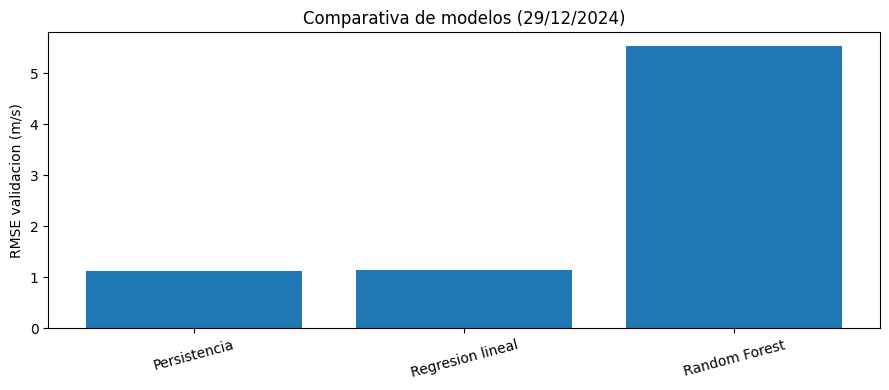

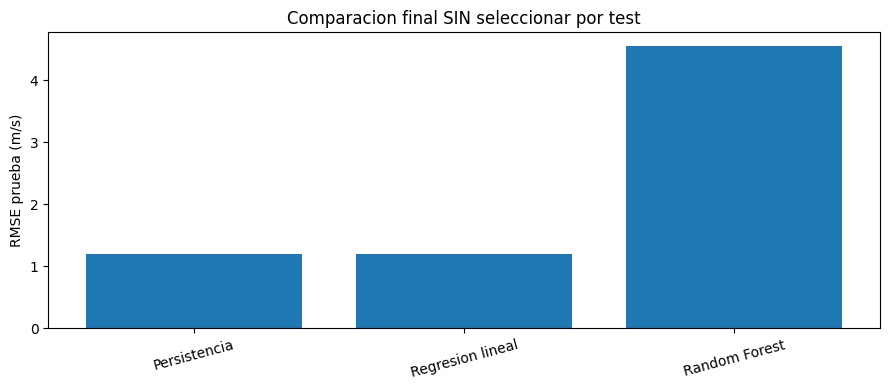

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


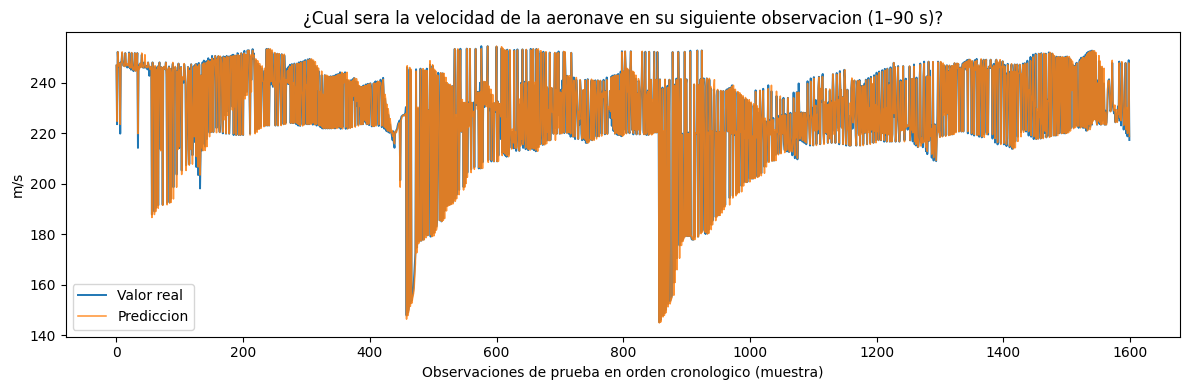

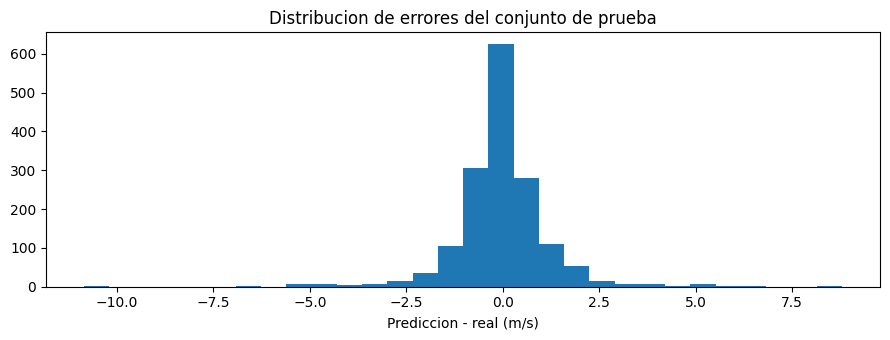

RESPUESTA A LA PREGUNTA: ¿Cual sera la velocidad de la aeronave en su siguiente observacion (1–90 s)?
Modelo seleccionado: Persistencia
Metricas en prueba (30/12): {'rmse': 1.1961620859384992, 'mae': 0.6501460705825931, 'r2': 0.9964619694930871}


In [8]:
import matplotlib.pyplot as plt
import pandas as pd

fig,ax=plt.subplots(figsize=(9,4))
ax.bar(tabla['modelo'],tabla['rmse_val'])
ax.set_ylabel('RMSE validacion ('+UNIDAD+')'); ax.set_title('Comparativa de modelos (29/12/2024)')
ax.tick_params(axis='x',rotation=15)
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(9,4))
ax.bar(tabla['modelo'],tabla['rmse_test'])
ax.set_ylabel('RMSE prueba ('+UNIDAD+')');ax.set_title('Comparacion final SIN seleccionar por test')
ax.tick_params(axis='x',rotation=15)
plt.tight_layout();plt.show()

vista=resultado_test.orderBy(*ORDEN_SALIDA).limit(1600).toPandas()
fig,ax=plt.subplots(figsize=(12,4))
if 'inicio' in vista.columns:
    eje=pd.to_datetime(vista['siguiente_inicio'] if 'siguiente_inicio' in vista.columns else vista['fin'])
    ax.set_xlabel('Ventana objetivo (UTC, 30/12/2024)')
else:
    eje=range(len(vista))
    ax.set_xlabel('Observaciones de prueba en orden cronologico (muestra)')
ax.plot(eje,vista['label'],label='Valor real',lw=1.4)
ax.plot(eje,vista['prediction'],label='Prediccion',lw=1.1,alpha=.85)
ax.set_ylabel(UNIDAD);ax.set_title(PREGUNTA)
ax.legend();plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(9,3.5))
ax.hist(vista['error'].dropna(),bins=30)
ax.set_title('Distribucion de errores del conjunto de prueba')
ax.set_xlabel('Prediccion - real ('+UNIDAD+')')
plt.tight_layout();plt.show()

print('RESPUESTA A LA PREGUNTA:',PREGUNTA)
print('Modelo seleccionado:',seleccionado)
print('Metricas en prueba (30/12):',metricas(resultado_test))


## 7. Guardar modelo, pruebas y comparativa

In [9]:
# Guardar los modelos ML realmente entrenados y el candidato elegido.
MODELO_RUTA=str(ROOT/'models'/ID_MODELO)
Path(MODELO_RUTA).parent.mkdir(parents=True,exist_ok=True)
ml_mejor=tabla_validacion[tabla_validacion.modelo!='Persistencia'].iloc[0]['modelo']
modelos[ml_mejor].write().overwrite().save(MODELO_RUTA)
recargado=PipelineModel.load(MODELO_RUTA)
if seleccionado!='Persistencia':
    assert seleccionado==ml_mejor
print('Modelo ML validado, guardado y recargado:',ml_mejor,MODELO_RUTA)
if seleccionado=='Persistencia':
    print('IMPORTANTE: la seleccion operativa es persistencia; NO usar el ML cargado para inferencia.')

SALIDA_TEST=str(ROOT/'evaluacion'/ID_MODELO)
(resultado_test.withColumn('sourceDataset',F.lit('adsblol_globe_history'))
    .coalesce(1).write.mode('overwrite').parquet(SALIDA_TEST))
TABLA_CSV=str(ROOT/f'comparativa_{ID_MODELO}.csv')
tabla.to_csv(TABLA_CSV,index=False)
config={'dataset':'ADSB.lol Peru 2024-12-26 a 2024-12-30',
 'modelo_seleccionado':seleccionado,'mejor_modelo_ml':ml_mejor,
 'modelo_ml_path':MODELO_RUTA,'evaluacion_path':SALIDA_TEST,
 'criterio':'RMSE de validacion (2024-12-29), prueba final 2024-12-30',
 'pregunta':PREGUNTA,'caracteristicas':FEATURES,
 'metricas':tabla.to_dict(orient='records'),
 'origen_temporal':'historico ADSB.lol 2024 (replay 2026 separado)'}
(ROOT/f'seleccion_{ID_MODELO}.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
print('Comparativa:',TABLA_CSV)
print('Predicciones verificadas:',SALIDA_TEST)


Modelo ML validado, guardado y recargado: Regresion lineal /workspace/artifacts/s10/models/jhonatan_velocidad
IMPORTANTE: la seleccion operativa es persistencia; NO usar el ML cargado para inferencia.


Comparativa: /workspace/artifacts/s10/comparativa_jhonatan_velocidad.csv
Predicciones verificadas: /workspace/artifacts/s10/evaluacion/jhonatan_velocidad


## 8. Inferencia opcional desde Kafka (S10 y demostración S12)
- **Por defecto no inicia**. Primero ejecutar entrenamiento y comprobar los resultados de prueba.
- Fuente `aeronaves-telemetria` = eventos nuevos de OpenSky con `source=opensky`.
- El topic `aeronaves-telemetria-historica-peru` contiene eventos históricos de 2024 con un reloj de demostración en 2026: se comprueba en la sección 9, **sin mezclarlos en el mismo cálculo de tiempo real**.
- **No confundir** la predicción realizada sobre una lectura con error medido en vivo: para medir este último es necesario emparejarla con una observación futura verificable. Los resultados batch ya incluyen `label`, `prediction` y `error` para S11.
- Para una segunda ejecución con el mismo checkpoint, no borres archivos al azar ni inicies una copia simultánea.


In [10]:
# Inferencia sin estado desde Kafka: cada observación contiene todas las features.
INICIAR_STREAM=True
if INICIAR_STREAM:
    ESQ='eventType string, schemaVersion int, icao24 string, eventTime string, latitude double, longitude double, velocity double, baroAltitude double, verticalRate double, trueTrack double, source string'
    raw=(spark.readStream.format('kafka').option('kafka.bootstrap.servers','kafka:9092')
         .option('subscribe','aeronaves-telemetria')
         .option('startingOffsets','latest').load())
    vivos=(raw.select(F.from_json(F.col('value').cast('string'),ESQ).alias('j')).select('j.*')
       .withColumn('eventTimestamp',F.to_timestamp('eventTime'))
       .filter((F.col('source')=='opensky')&(F.col('schemaVersion')==1))
       .filter(F.col('icao24').rlike('^[0-9a-f]{6}$') & F.col('eventTimestamp').isNotNull())
       .filter(F.col('velocity').between(0,400))
       .filter(F.col('latitude').between(-18.35,-0.04)&F.col('longitude').between(-81.33,-68.65))
       .fillna({'baroAltitude':0.0,'verticalRate':0.0,'trueTrack':0.0})
       .withColumn('hora_decimal',F.hour('eventTimestamp')+F.minute('eventTimestamp')/60.0)
       .withColumn('hora_sin',F.sin(F.col('hora_decimal')*F.lit(2*math.pi/24)))
       .withColumn('hora_cos',F.cos(F.col('hora_decimal')*F.lit(2*math.pi/24)))
       .withColumn('dia_semana',F.dayofweek('eventTimestamp').cast('double')))
    def guardar_pred_jhonatan(lote,batch_id):
        if lote.isEmpty(): return
        pred=(lote.withColumn('prediction',F.col('velocity').cast('double')) if seleccionado=='Persistencia'
              else recargado.transform(lote))
        salida=(pred.select('icao24','eventTimestamp','velocity','prediction')
            .withColumn('modelo',F.lit(seleccionado))
            .withColumn('fuente',F.lit('opensky_live'))
            .withColumn('batch_id',F.lit(batch_id)))
        salida.write.mode('append').parquet(str(ROOT/'predicciones_live'/'jhonatan'))
        salida.show(5,False)
    stream_jhonatan=(vivos.writeStream.outputMode('append')
        .foreachBatch(guardar_pred_jhonatan)
        .option('checkpointLocation','/workspace/artifacts/checkpoints/s10_jhonatan_live_v3')
        .trigger(processingTime='30 seconds').start())
    print('STREAM ACTIVO:',stream_jhonatan.isActive)
else:
    print('No hay stream iniciado. Activa solo para el ensayo con nuevos eventos OpenSky.')


STREAM ACTIVO: True


## 9. Auditoría de los 184 766 eventos del histórico publicado en Kafka
La comparación de offsets/JSON es **batch** y opcional; no se confunde con inferencia en vivo. El topic ya fue publicado, así que no hay que volver a enviarlo.

In [11]:
# PRUEBA DE INGESTA: ver mensajes históricos YA publicados en Kafka (batch; sin duplicarlos).
# Esta sección es independiente del entrenamiento y es opcional.
LEER_KAFKA_HISTORICO=False
if LEER_KAFKA_HISTORICO:
    KAFKA_TOPIC_HIST='aeronaves-telemetria-historica-peru'
    k=(spark.read.format('kafka')
       .option('kafka.bootstrap.servers','kafka:9092')
       .option('subscribe',KAFKA_TOPIC_HIST)
       .option('startingOffsets','earliest').option('endingOffsets','latest').load())
    print('Eventos disponibles en Kafka (sin modificaciones):',k.count())
    j=(k.select(F.from_json(F.col('value').cast('string'),
       'icao24 string, eventTime string, originalEventTime string, historicalReplay boolean, velocity double, source string').alias('e')).select('e.*'))
    j.groupBy('source','historicalReplay').count().show(truncate=False)
    j.select('icao24','originalEventTime','eventTime','velocity').show(5,False)
    print('Estos eventos son mediciones de 2024 reproducidas con reloj 2026; NO sustituir fechas de entrenamiento.')
else:
    print('Verificacion de Kafka historico desactivada. Cambia LEER_KAFKA_HISTORICO=True si la necesitas.')


Verificacion de Kafka historico desactivada. Cambia LEER_KAFKA_HISTORICO=True si la necesitas.


## 9. Limitaciones e interpretación
- Los pares son de **1 a 90 segundos**, no exactamente a 60 segundos.
- Los datos proceden del espacio aéreo de Perú en cinco jornadas; no prueban generalización para todo el año.
- Si la persistencia supera a los modelos, es una conclusión válida.
- La evaluación separa días pero no ICAO24 entre entrenamiento y test.
- No confundir `eventTime` desplazado de noviembre de 2026 con la fecha de observación original.
- OpenSky actual puede tener cobertura distinta a ADSB.lol histórico; verificar desempeño en vivo antes de afirmar exactitud operativa.

**Criterios S12 pendientes fuera de este notebook:** consumer IoT, logs watermark/checkpoint del pipeline, costos escalado y tablero BI Grafana con batch y streaming y errores medidos en vivo. No se dan por cumplidos automáticamente.

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

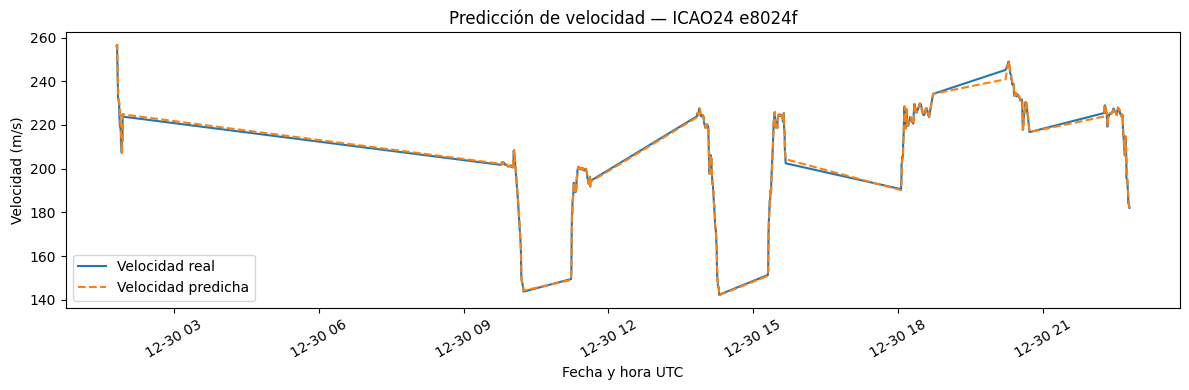

In [12]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

icao = (
    resultado_test
    .groupBy("icao24")
    .count()
    .orderBy(F.desc("count"))
    .first()["icao24"]
)

grafico = (
    resultado_test
    .filter(F.col("icao24") == icao)
    .orderBy("eventTimestamp")
    .select("eventTimestamp", "label", "prediction")
    .toPandas()
)

plt.figure(figsize=(12, 4))
plt.plot(grafico["eventTimestamp"], grafico["label"],
         label="Velocidad real")
plt.plot(grafico["eventTimestamp"], grafico["prediction"],
         label="Velocidad predicha", linestyle="--")

plt.title(f"Predicción de velocidad — ICAO24 {icao}")
plt.xlabel("Fecha y hora UTC")
plt.ylabel("Velocidad (m/s)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [13]:
print("STREAM ACTIVO:", stream_jhonatan.isActive)
print("ESTADO:", stream_jhonatan.status)
print("ERROR:", stream_jhonatan.exception())

p = stream_jhonatan.lastProgress

if p:
    print("LOTE:", p.get("batchId"))
    print("FILAS RECIBIDAS:", p.get("numInputRows"))
    print("DURACIÓN DEL LOTE:", p.get("batchDuration"))
else:
    print("Todavía no hay un microlote completado")

STREAM ACTIVO: True
ESTADO: {'message': 'Processing new data', 'isDataAvailable': True, 'isTriggerActive': True}
ERROR: None
Todavía no hay un microlote completado


In [14]:
import os
from pyspark.sql import functions as F

RUTA_JHONATAN = "/workspace/artifacts/s10/predicciones_live/jhonatan"

if os.path.isdir(RUTA_JHONATAN):
    archivos = [
        nombre for nombre in os.listdir(RUTA_JHONATAN)
        if nombre.endswith(".parquet")
    ]

    if archivos:
        pred = spark.read.parquet(RUTA_JHONATAN)

        print("PREDICCIONES GENERADAS:", pred.count())

        pred.orderBy(
            F.desc("eventTimestamp")
        ).show(15, truncate=False)
    else:
        print("No hay archivos Parquet todavía.")
else:
    print("Todavía no se ha generado ninguna predicción.")

PREDICCIONES GENERADAS: 8


[Stage 233:>                (0 + 1) / 1][Stage 238:========>        (1 + 1) / 2]

+------+-------------------+--------+----------+------------+------------+--------+
|icao24|eventTimestamp     |velocity|prediction|modelo      |fuente      |batch_id|
+------+-------------------+--------+----------+------------+------------+--------+
|e80212|2026-11-06 18:18:56|227.86  |227.86    |Persistencia|opensky_live|7       |
|e80212|2026-11-06 18:16:53|230.61  |230.61    |Persistencia|opensky_live|6       |
|e80212|2026-11-06 18:14:55|236.21  |236.21    |Persistencia|opensky_live|5       |
|e8027c|2026-11-06 17:55:47|218.35  |218.35    |Persistencia|opensky_live|4       |
|e8027c|2026-11-06 17:54:41|228.24  |228.24    |Persistencia|opensky_live|3       |
|e8027c|2026-11-06 17:52:37|242.97  |242.97    |Persistencia|opensky_live|2       |
|e80211|2026-11-06 17:52:24|242.17  |242.17    |Persistencia|opensky_live|2       |
|e80244|2026-11-06 17:48:37|240.14  |240.14    |Persistencia|opensky_live|1       |
+------+-------------------+--------+----------+------------+------------+--

In [15]:
from pyspark.sql import functions as F

ruta = "/workspace/artifacts/s10/predicciones_live/jhonatan"

pred = spark.read.parquet(ruta)

pred.agg(
    F.count("*").alias("predicciones"),
    F.countDistinct("icao24").alias("aeronaves")
).show()

pred.orderBy(F.desc("eventTimestamp")).show(10, False)

+------------+---------+
|predicciones|aeronaves|
+------------+---------+
|           8|        4|
+------------+---------+

+------+-------------------+--------+----------+------------+------------+--------+
|icao24|eventTimestamp     |velocity|prediction|modelo      |fuente      |batch_id|
+------+-------------------+--------+----------+------------+------------+--------+
|e80212|2026-11-06 18:18:56|227.86  |227.86    |Persistencia|opensky_live|7       |
|e80212|2026-11-06 18:16:53|230.61  |230.61    |Persistencia|opensky_live|6       |
|e80212|2026-11-06 18:14:55|236.21  |236.21    |Persistencia|opensky_live|5       |
|e8027c|2026-11-06 17:55:47|218.35  |218.35    |Persistencia|opensky_live|4       |
|e8027c|2026-11-06 17:54:41|228.24  |228.24    |Persistencia|opensky_live|3       |
|e8027c|2026-11-06 17:52:37|242.97  |242.97    |Persistencia|opensky_live|2       |
|e80211|2026-11-06 17:52:24|242.17  |242.17    |Persistencia|opensky_live|2       |
|e80244|2026-11-06 17:48:37|240.14

In [16]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import os

# Crear o recuperar la sesión de Spark
spark = (
    SparkSession.builder
    .appName("S11_Verificacion_Jhonatan")
    .master("local[*]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

# Ruta de predicciones de Jhonatan
ruta = "/workspace/artifacts/s10/predicciones_live/jhonatan"

if os.path.exists(ruta):
    pred = spark.read.parquet(ruta)

    print("=== RESUMEN DE PREDICCIONES ===")

    pred.agg(
        F.count("*").alias("predicciones_guardadas"),
        F.countDistinct("icao24").alias("aeronaves_distintas"),
        F.max("eventTimestamp").alias("ultima_observacion")
    ).show(truncate=False)

    print("=== ÚLTIMAS 10 PREDICCIONES ===")

    pred.orderBy(
        F.desc("eventTimestamp")
    ).show(10, truncate=False)

else:
    print("Todavía no existe la carpeta de predicciones.")
    print("Ruta:", ruta)

=== RESUMEN DE PREDICCIONES ===
+------+-------------------+--------+----------+------------+------------+--------+
|icao24|eventTimestamp     |velocity|prediction|modelo      |fuente      |batch_id|
+------+-------------------+--------+----------+------------+------------+--------+
|e80463|2026-11-06 18:25:04|223.72  |223.72    |Persistencia|opensky_live|8       |
+------+-------------------+--------+----------+------------+------------+--------+

+----------------------+-------------------+-------------------+
|predicciones_guardadas|aeronaves_distintas|ultima_observacion |
+----------------------+-------------------+-------------------+
|9                     |5                  |2026-11-06 18:25:04|
+----------------------+-------------------+-------------------+

=== ÚLTIMAS 10 PREDICCIONES ===
+------+-------------------+--------+----------+------------+------------+--------+
|icao24|eventTimestamp     |velocity|prediction|modelo      |fuente      |batch_id|
+------+-------------

In [17]:
print("Activo:", stream_jhonatan.isActive)
print("Error:", stream_jhonatan.exception())
print("Último progreso:", stream_jhonatan.lastProgress)

Activo: True
Error: None
Último progreso: {
    "id": "8088a8d3-9871-482f-905c-f465e733630d",
    "runId": "e0c5f1a0-ec87-42a1-bbdb-ee6cc843ba66",
    "name": null,
    "timestamp": "2026-11-06T19:41:16.986Z",
    "batchId": 8,
    "batchDuration": 10687,
    "numInputRows": 3,
    "inputRowsPerSecond": 0.0,
    "processedRowsPerSecond": 0.3,
    "durationMs": {
        "addBatch": 9667,
        "commitOffsets": 596,
        "getBatch": 38,
        "queryPlanning": 350,
        "triggerExecution": 10678
    },
    "stateOperators": [],
    "sources": [
        {
            "description": "KafkaV2[Subscribe[aeronaves-telemetria]]",
            "startOffset": {
                "aeronaves-telemetria": {
                    "0": 180,
                    "1": 185,
                    "2": 248
                }
            },
            "endOffset": {
                "aeronaves-telemetria": {
                    "0": 180,
                    "1": 186,
                    "2": 248
         

+------+-------------------+--------+----------+------------+------------+--------+
|icao24|eventTimestamp     |velocity|prediction|modelo      |fuente      |batch_id|
+------+-------------------+--------+----------+------------+------------+--------+
|4cadab|2026-11-06 18:33:17|236.85  |236.85    |Persistencia|opensky_live|9       |
|4cadab|2026-11-06 18:35:15|239.77  |239.77    |Persistencia|opensky_live|9       |
|e8045c|2026-11-06 18:36:33|227.26  |227.26    |Persistencia|opensky_live|9       |
|4cadab|2026-11-06 18:37:19|236.43  |236.43    |Persistencia|opensky_live|9       |
|4cadab|2026-11-06 18:39:18|232.29  |232.29    |Persistencia|opensky_live|9       |
+------+-------------------+--------+----------+------------+------------+--------+
only showing top 5 rows
